<a href="https://colab.research.google.com/github/santhosh830100-bit/FDS_LAB_EXPERIMENTS/blob/main/EXP_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
data='/content/fds2.csv'
df=pd.read_csv(data)
print(df.head())


  Product  Quantity    Sales Region        Date
0  Laptop       2.0  80000.0  South  2026-01-01
1  Mobile       5.0  50000.0  North  2026-01-02
2  Laptop       1.0  40000.0  South  2026-01-03
3  Tablet       3.0  30000.0   East  2026-01-04
4  Mobile       4.0  40000.0   West  2026-01-05


In [ ]:
print(df.isnull().sum())

Product     1
Quantity    1
Sales       1
Region      1
Date        0
dtype: int64


In [ ]:
df['Sales'].fillna(df['Sales'].mean(),inplace=True)
print(df.isnull().sum())
df.dropna(subset=['Sales','Product','Quantity','Region'],inplace=True)
print(df.isnull().sum())

Product     1
Quantity    1
Sales       0
Region      1
Date        0
dtype: int64
Product     0
Quantity    0
Sales       0
Region      0
Date        0
dtype: int64


/tmp/ipykernel_1152/616280879.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Sales'].fillna(df['Sales'].mean(),inplace=True)


In [ ]:
ps=df.groupby('Product').agg({
    'Sales':'sum',
    'Quantity':'sum'
}).reset_index()
print(ps)

  Product          Sales  Quantity
0  Laptop  320000.000000       8.0
1  Mobile  155000.000000      14.0
2  Tablet  139642.857143      14.0


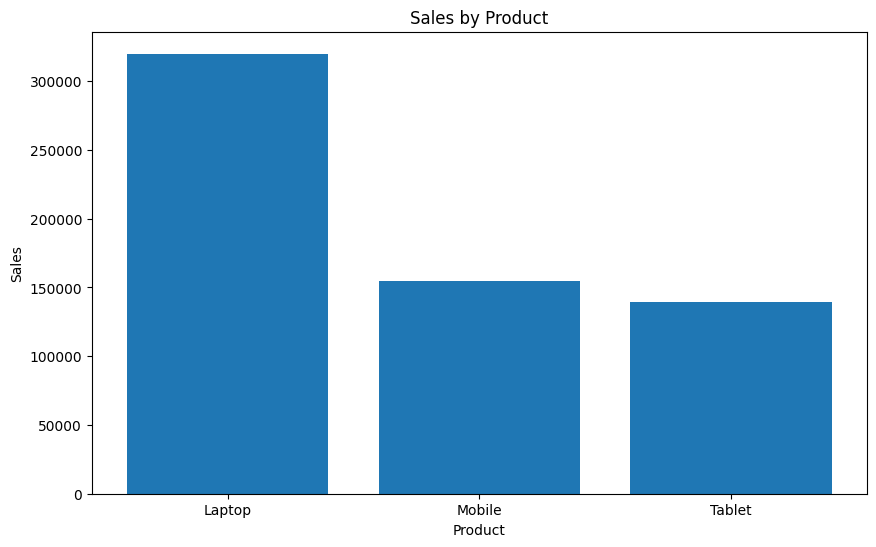

In [ ]:
plt.figure(figsize=(10,6))
plt.bar(ps['Product'],ps['Sales'])
plt.xlabel('Product')
plt.ylabel('Sales')
plt.title('Sales by Product')
plt.show()

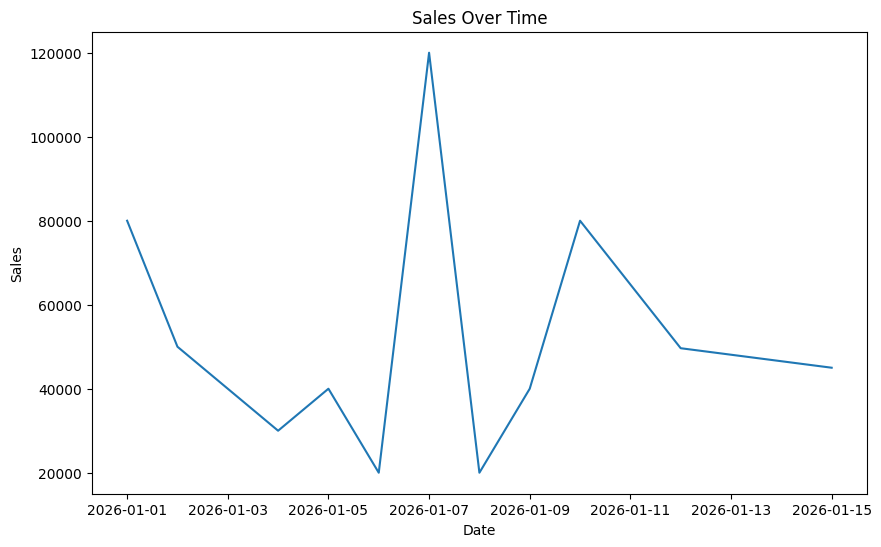

In [ ]:
df['Date']=pd.to_datetime(df['Date'])
s=df.groupby('Date').agg({
    'Sales':'sum'
}).reset_index()
plt.figure(figsize=(10,6))
plt.plot(s['Date'],s['Sales'])
plt.title('Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.show()

In [ ]:
p=df.pivot_table(values='Sales',index='Region',columns='Product',aggfunc=np.sum,fill_value=0)
print(p)

Product    Laptop   Mobile   Tablet
Region                             
East      80000.0  45000.0  50000.0
North    120000.0  80000.0      0.0
South    120000.0  20000.0      0.0
West          0.0  40000.0  40000.0


/tmp/ipykernel_1152/1695677194.py:1: FutureWarning: The provided callable <function sum at 0x7f3ff7994ea0> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  p=df.pivot_table(values='Sales',index='Region',columns='Product',aggfunc=np.sum,fill_value=0)


In [ ]:
c=df.corr(numeric_only=True)
print(c)

          Quantity     Sales
Quantity  1.000000  0.061974
Sales     0.061974  1.000000


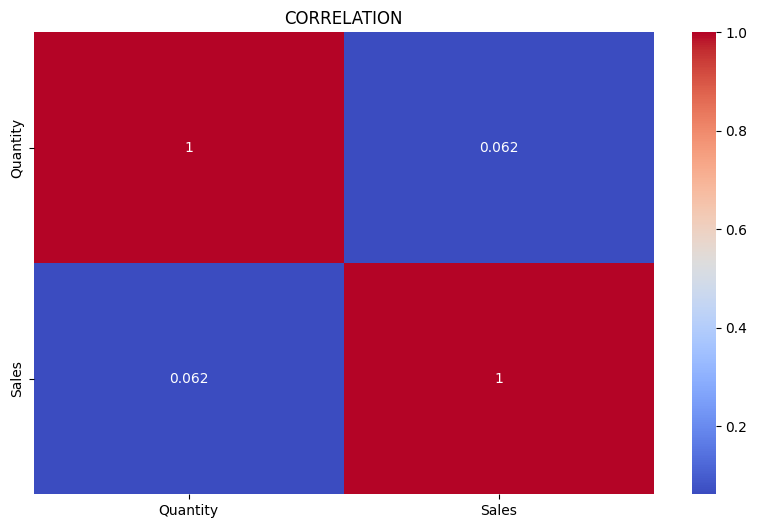

In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(c,annot=True,cmap='coolwarm')
plt.title('CORRELATION')
plt.show()